# Homework 2: emissions and trade

The question and submission instructions are in `assignment.pdf`.

`data/co2_2023.csv` contains one country per row for 2023, with population and territorial and consumption-based CO2 emissions. The estimates come from Our World in Data and the Global Carbon Budget. `data/countries.geojson` contains Natural Earth country names, identifiers and boundary geometries. Definitions and sources are in `data/README.md`.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

emissions = pd.read_csv("data/co2_2023.csv")
emissions.head()

,country,iso_code,year,population,co2,co2_per_capita,consumption_co2,consumption_co2_per_capita
0,Afghanistan,AFG,2023,41454762.0,10.516,0.254,NaN,NaN
1,Albania,ALB,2023,2811660.0,4.417,1.571,5.382,1.914
2,Algeria,DZA,2023,46164222.0,202.847,4.394,NaN,NaN
3,Angola,AGO,2023,36749909.0,21.675,0.590,NaN,NaN
4,Argentina,ARG,2023,45538402.0,178.407,3.918,185.666,4.077


In [2]:
import geopandas as gpd

countries = gpd.read_file("data/countries.geojson")
countries.head()

,iso_code,map_name,geometry
0,FJI,Fiji,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,TZA,United Republic of Tanzania,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,ESH,Western Sahara,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,CAN,Canada,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,USA,United States of America,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


In [5]:
world = countries.merge(emissions, on="iso_code", how="left", validate="one_to_one", indicator=True)
world["diff"] = world["consumption_co2_per_capita"] - world["co2_per_capita"]
projected = world.to_crs("EPSG:8857")

diff_summary = projected["diff"].describe()
cols = ["map_name", "co2_per_capita", "consumption_co2_per_capita", "diff"]


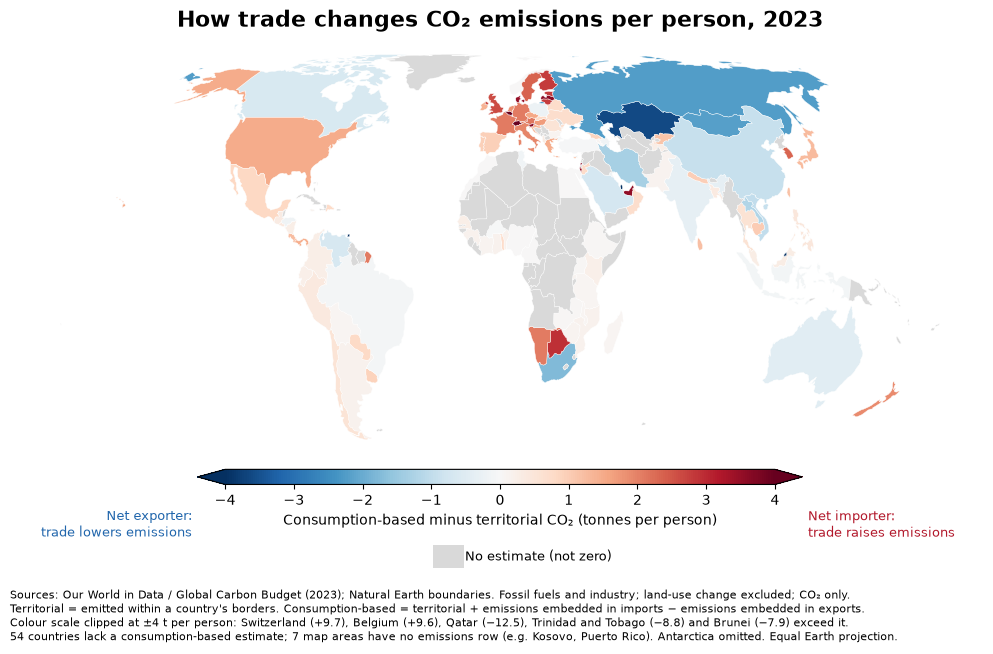

In [103]:
fig, ax = plt.subplots(figsize=(14, 7))
fig.subplots_adjust(left=0.02, right=0.98, top=0.90, bottom=0.17)

projected.plot(column="diff", cmap="RdBu_r", vmin=-4, vmax=4, ax=ax,
               edgecolor="white", linewidth=0.3,
               legend=True,
               legend_kwds={"orientation": "horizontal", "shrink": 0.45, "pad": 0.02, "aspect": 40,
                            "label": "Consumption-based minus territorial CO₂ (tonnes per person)"},
               missing_kwds={"color": "#d9d9d9", "label": "No estimate"})

ax.set_axis_off()

ax.set_title("How trade changes CO₂ emissions per person, 2023", ha="center", fontsize=16, fontweight="bold")

fig.text(0.28, 0.20, "Net exporter:\ntrade lowers emissions", ha="right", va="center", fontsize=9, color="#2166ac")
fig.text(0.72, 0.20, "Net importer:\ntrade raises emissions", ha="left", va="center", fontsize=9, color="#b2182b")

fig.text(0.47, 0.155, "     ", ha="right", va="center", fontsize=9,
         bbox=dict(facecolor="#d9d9d9", edgecolor="none"))
fig.text(0.475, 0.155, "No estimate (not zero)", ha="left", va="center", fontsize=9)

fig.text(0.15, 0.03,
    "Sources: Our World in Data / Global Carbon Budget (2023); Natural Earth boundaries. Fossil fuels and industry; land-use change excluded; CO₂ only.\n"
    "Territorial = emitted within a country's borders. Consumption-based = territorial + emissions embedded in imports − emissions embedded in exports.\n"
    "Colour scale clipped at ±4 t per person: Switzerland (+9.7), Belgium (+9.6), Qatar (−12.5), Trinidad and Tobago (−8.8) and Brunei (−7.9) exceed it.\n"
    "54 countries lack a consumption-based estimate; 7 map areas have no emissions row (e.g. Kosovo, Puerto Rico). Antarctica omitted. Equal Earth projection.",
    fontsize=8, va="bottom")

fig.savefig("figures/submission.png", dpi=150)
plt.show()